# w2 · LSTM vs GRU for churn (PyTorch)

Two recurrent models, an **LSTM** and a **GRU**, predict churn from the **90-day × 20-channel** tensors built in `w2_sequence_preprocessing.ipynb`.

The primary KPI is **log-loss**, because it measures the quality of the predicted probabilities. The evaluation is temporal:

| Part | Cohort | Use |
|---|---|---|
| `fit` | February | training |
| `stop` | February | validation and early stopping |
| `tune` | February | Optuna selection and threshold |
| `test` | March | final evaluation, once |
| `development` | All February | final refit |

Both models go through exactly the same pipeline: same split, same base seed, same Optuna budget (`N_TRIALS`), same search space and the same threshold rule. Only the recurrent cell changes. The notebook only orchestrates the pieces that live in `src/models/recurrent_models/` and `src/models/evaluation/`.

## 1. Configuration

The model settings, paths and Optuna budget live in `src/models/recurrent_models/config.py`. Here they are imported and displayed so it is explicit what the run uses.

- `N_TRIALS=5`: five candidate configurations **per model**.
- `EPOCHS=40`: maximum epochs per trial.
- `PATIENCE=5`: early stopping when `stop` does not improve for five epochs.
- `BATCH_SIZE=512`: block/batch size.
- `layer_dim` is searched between 2 and 4; `hidden_dim` among 32, 64 and 128.
- `lr` and `weight_decay` are searched on a logarithmic scale.

Each model writes to its own folder, `artifacts/sherlock_w2/<model>/` (`optuna/`, `checkpoints/`, `evaluation/`). The side-by-side outputs go to `artifacts/sherlock_w2/comparison/`.

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Image, display

warnings.filterwarnings("ignore")

from src.models.recurrent_models.config import (
    BATCH_SIZE,
    EPOCHS,
    EXPORT_DIR,
    FEATURE_DIR,
    HIDDEN_DIMS,
    INPUT_DIM,
    LAYER_DIM_RANGE,
    LR_RANGE,
    N_TRIALS,
    OUTPUT_DIM,
    PATIENCE,
    SEED,
    WEIGHT_DECAY_RANGE,
    model_dirs,
)
from src.models.recurrent_models.recurrent_classifier import GRUModel, LSTMModel
from src.models.recurrent_models.train import resolve_device
from src.models.evaluation.compare import COMPARISON_DIR

DEVICE = resolve_device()

# model_name -> model class. Every loop below iterates over this dict.
MODELS = {"lstm": LSTMModel, "gru": GRUModel}

settings = pd.DataFrame(
    [
        ("models", ", ".join(name.upper() for name in MODELS)),
        ("export_dir", str(EXPORT_DIR)),
        ("feature_dir", str(FEATURE_DIR)),
        ("comparison_dir", str(COMPARISON_DIR)),
        ("device", str(DEVICE)),
        ("seed", SEED),
        ("n_trials", N_TRIALS),
        ("epochs", EPOCHS),
        ("patience", PATIENCE),
        ("batch_size", BATCH_SIZE),
        ("input_dim", INPUT_DIM),
        ("output_dim", OUTPUT_DIM),
        ("hidden_dims", HIDDEN_DIMS),
        ("layer_dim_range", LAYER_DIM_RANGE),
        ("lr_range", LR_RANGE),
        ("weight_decay_range", WEIGHT_DECAY_RANGE),
    ],
    columns=["setting", "value"],
)
display(settings)

# Artifact folders per model.
pd.DataFrame({name.upper(): {k: str(v) for k, v in model_dirs(name).items()} for name in MODELS})

,setting,value
0,models,"LSTM, GRU"
1,export_dir,export-sequential-v5
2,feature_dir,artifacts/sherlock_w2/feature_preparation
3,comparison_dir,artifacts/sherlock_w2/comparison
4,device,cuda
5,seed,110
6,n_trials,5
7,epochs,40
8,patience,5
9,batch_size,512


,LSTM,GRU
artifacts,artifacts/sherlock_w2/lstm,artifacts/sherlock_w2/gru
optuna,artifacts/sherlock_w2/lstm/optuna,artifacts/sherlock_w2/gru/optuna
checkpoints,artifacts/sherlock_w2/lstm/checkpoints,artifacts/sherlock_w2/gru/checkpoints
evaluation,artifacts/sherlock_w2/lstm/evaluation,artifacts/sherlock_w2/gru/evaluation


## 2. Feature preparation

### 2.1 Data

`export-sequential-v5` contains a `(users, 90, 20)` `float16` tensor, with days ordered from oldest to newest. The channels are:

- `0:8`: listening. Seven counters transformed with `log1p` plus the `active` flag.
- `8:13`: daily transaction events.
- `13:20`: subscription state propagated forward.

The `is_churn` labels are aligned row by row with the tensor. Everything is computed from information available up to each cohort cutoff, so there is no temporal leakage.

The tensors are read with `mmap_mode="r"`; they are never fully loaded into RAM.

In [2]:
from src.models.recurrent_models.data import load_prepared_data

data = load_prepared_data(feature_dir=FEATURE_DIR, export_dir=EXPORT_DIR)

print("tensor:", data.view.shape, data.view.dtype)
print("input_dim:", data.input_dim)
print("channels:", data.meta["sequences"]["lstm"]["channels"])
print("split sizes:", {part: len(rows) for part, rows in data.split.items()})
for part in ("fit", "stop", "tune", "test"):
    labels = data.labels(part)
    print(f"{part:4s} n={len(labels):>9,} | churn_rate={labels.mean():.4f}")

train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 4) | users in both months: 881701
tensor: (1963891, 90, 20) float16
input_dim: 20
channels: ['num_25', 'num_50', 'num_75', 'num_985', 'num_100', 'num_unq', 'total_secs', 'active', 'tx_count', 'tx_paid_sum', 'tx_plan_days_sum', 'tx_cancel_count', 'tx_auto_renew_count', 'tx_state_known', 'tx_last_is_cancel', 'tx_last_is_auto_renew', 'tx_days_since_last', 'tx_days_to_expire', 'tx_expiry_known', 'tx_state_ambiguous']
split sizes: {'fit': 744699, 'stop': 124117, 'tune': 124115, 'test': 970960, 'development': 992931}
fit  n=  744,699 | churn_rate=0.0639
stop n=  124,117 | churn_rate=0.0639
tune n=  124,115 | churn_rate=0.0639
test n=  970,960 | churn_rate=0.0899


### 2.2 Split

February is split once with a stable `msno` hash, stratified by label:

- `fit`: 75%.
- `stop`: 12.5%.
- `tune`: 12.5%.
- `test`: all of March, never used for any decision.
- `development`: all of February; used only for the final refit before predicting March.

This keeps the threshold honest: it is selected on `tune` and never re-searched on `test`.

In [3]:
split_table = pd.DataFrame(
    [
        {
            "part": part,
            "n_users": len(data.split[part]),
            "churn_rate": float(data.labels(part).mean()),
        }
        for part in ("fit", "stop", "tune", "test", "development")
    ]
)
split_table

,part,n_users,churn_rate
0,fit,744699,0.063924
1,stop,124117,0.063924
2,tune,124115,0.063917
3,test,970960,0.089942
4,development,992931,0.063923


### 2.3 Prepared dataset and batches

The existing `PreparedSequenceData` class encapsulates:

- the labels,
- the split indices,
- the memory-mapped tensor view,
- the scalers fitted per phase.

Its `iter_batches` method returns blocks of transformed rows as PyTorch tensors. It does not transform row by row: it reads blocks to reduce overhead and keep memory usage bounded.

- `phase="fit"`: scaler fitted only on `fit`.
- `phase="development"`: scaler fitted on all of February.
- `drop_last=True`: avoids a final batch of size 1, which `BatchNorm1d` cannot normalise during training.

In [4]:
sample_rows = data.rows("fit")[:BATCH_SIZE]
xb, yb = next(
    iter(data.iter_batches(sample_rows, "fit", BATCH_SIZE, drop_last=True))
)
print("x:", xb.shape, xb.dtype)
print("y:", yb.shape, yb.dtype)
print("first user, channel 0, day 0:", float(xb[0, 0, 0]))

x: torch.Size([512, 90, 20]) torch.float32
y: torch.Size([512, 1]) torch.float32
first user, channel 0, day 0: 0.0


## 3. Model and training

### 3.1 Architecture: LSTM and GRU

The input is `(batch, 90, 20)`. Both networks stack between **2 and 4 recurrent layers** and share the same head; only the recurrent cell changes (`RecurrentClassifier` with `rnn_cls = nn.LSTM` or `nn.GRU`).

- **LSTM**: input, forget and output gates plus a cell state `c_t`. Four weight blocks per layer.
- **GRU**: update and reset gates, no separate cell state. Three weight blocks per layer, so about **25% fewer parameters** for the same `hidden_dim` and usually faster epochs.

In both cases the last hidden output `h_T` summarises the 90-day history. After `h_T`:

1. `BatchNorm1d(hidden_dim)` stabilises the hidden-state distribution.
2. `Linear(hidden_dim, 1)` produces a logit.
3. At prediction time, `Sigmoid` turns the logit into a churn probability.

`forward` returns only the logit, so both families expose the same interface. There is no dropout, as specified. Overfitting is controlled by `weight_decay`, BatchNorm and early stopping.

The loss is `BCEWithLogitsLoss`: the numerically stable version of binary cross-entropy that works directly with logits.

In [5]:
# Same configuration for both cells: same output shape, different parameter count.
for name, model_cls in MODELS.items():
    example = model_cls(
        input_dim=INPUT_DIM, hidden_dim=64, layer_dim=2, output_dim=OUTPUT_DIM
    ).to(DEVICE).eval()
    with torch.no_grad():
        logits = example(xb.to(DEVICE))
    n_params = sum(p.numel() for p in example.parameters())
    print(
        f"{name.upper():4s} | logits {tuple(logits.shape)} | parameters {n_params:,}"
        f" | example probabilities {torch.sigmoid(logits[:3]).cpu().numpy().ravel().round(3)}"
    )

LSTM | logits (512, 1) | parameters 55,489 | example probabilities [0.49  0.488 0.49 ]
GRU  | logits (512, 1) | parameters 41,665 | example probabilities [0.539 0.538 0.54 ]


### 3.2 Optimisation

- **AdamW** decouples weight decay from the adaptive step.
- `lr` and `weight_decay` are searched with Optuna.
- **Gradient clipping** at norm 1.0 for recurrent-network stability.
- **AMP** on GPU for speed.
- At most **40 epochs** per trial.
- **Early stopping** with `patience=5`: if `stop` does not improve, training stops and the best checkpoint is restored.
- No dropout.

### 3.3 Optuna

Optuna uses TPE and minimises `log_loss` on `tune`:

- trains on `fit`,
- validates on `stop`,
- evaluates on `tune`,
- restores the best `stop` state before computing the objective.

The search space is the same for both models:

- `layer_dim`: 2–4.
- `hidden_dim`: 32, 64, 128.
- `lr`: `1e-4` to `1e-2` on a logarithmic scale.
- `weight_decay`: `1e-6` to `1e-2` on a logarithmic scale.
- `batch_size`: fixed at 512.

Each study is written under `artifacts/sherlock_w2/<model>/optuna/`: the SQLite study, the trials CSV, the best-parameters JSON and the per-epoch history of the best trial.

In [6]:
from src.models.recurrent_models.tune import tune_model

best = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    best[name] = tune_model(
        data,
        model_name=name,
        recurrent_model_class=model_cls,
        n_trials=N_TRIALS,
        epochs=EPOCHS,
        patience=PATIENCE,
        batch_size=BATCH_SIZE,
        device=DEVICE,
        seed=SEED,
        verbose=True,
    )

pd.DataFrame(
    {
        name.upper(): {
            "tune log-loss": result["best_value"],
            "threshold": result["threshold"],
            "best epoch": result["best_epoch"],
            "stopped epoch": result["stopped_epoch"],
            "trial": result["trial_number"],
            **result["best_params"],
        }
        for name, result in best.items()
    }
)


===== LSTM =====
Optuna budget=5 | remaining=5


  0%|          | 0/5 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 32, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0 | epoch 01 | train=0.17858 | stop=0.15340
trial 0 | epoch 02 | train=0.15201 | stop=0.15054
trial 0 | epoch 03 | train=0.15021 | stop=0.15022
trial 0 | epoch 04 | train=0.14937 | stop=0.14929
trial 0 | epoch 05 | train=0.14943 | stop=0.14852
trial 0 | epoch 06 | train=0.14861 | stop=0.14892
trial 0 | epoch 07 | train=0.14826 | stop=0.14812
trial 0 | epoch 08 | train=0.14787 | stop=0.14830
trial 0 | epoch 09 | train=0.14775 | stop=0.14777
trial 0 | epoch 10 | train=0.14747 | stop=0.14788
trial 0 | epoch 11 | train=0.14722 | stop=0.14741
trial 0 | epoch 12 | train=0.14705 | stop=0.14803
trial 0 | epoch 13 | train=0.14682 | stop=0.14768
trial 0 | epoch 14 | train=0.14653 | stop=0.14759
trial 0 | epoch 15 | train=0.14639 | stop=0.14745
trial 0 | epoch 16 | train=0.14628 | stop=0.14745
trial 0 | early stop at epoch 16 (best epoch 11)
tri

  0%|          | 0/5 [00:00<?, ?it/s]

trial 0: starting | params={'layer_dim': 2, 'hidden_dim': 32, 'lr': 0.002285499365417053, 'weight_decay': 0.0005368494554109796, 'batch_size': 512}
trial 0 | epoch 01 | train=0.17525 | stop=0.15264
trial 0 | epoch 02 | train=0.14997 | stop=0.15044
trial 0 | epoch 03 | train=0.14897 | stop=0.14910
trial 0 | epoch 04 | train=0.14838 | stop=0.14757
trial 0 | epoch 05 | train=0.14803 | stop=0.14752
trial 0 | epoch 06 | train=0.14764 | stop=0.14802
trial 0 | epoch 07 | train=0.14744 | stop=0.14763
trial 0 | epoch 08 | train=0.14710 | stop=0.14779
trial 0 | epoch 09 | train=0.14692 | stop=0.14729
trial 0 | epoch 10 | train=0.14675 | stop=0.14687
trial 0 | epoch 11 | train=0.14649 | stop=0.14690
trial 0 | epoch 12 | train=0.14639 | stop=0.14747
trial 0 | epoch 13 | train=0.14616 | stop=0.14723
trial 0 | epoch 14 | train=0.14589 | stop=0.14701
trial 0 | epoch 15 | train=0.14573 | stop=0.14712
trial 0 | early stop at epoch 15 (best epoch 10)
trial 0: loss=0.14653 | best_epoch=10 | stopped=15 | 

,LSTM,GRU
tune log-loss,0.146742,0.146528
threshold,0.270000,0.240000
best epoch,11.000000,10.000000
stopped epoch,16.000000,15.000000
trial,0.000000,0.000000
layer_dim,2.000000,2.000000
hidden_dim,32.000000,32.000000
lr,0.002285,0.002285
weight_decay,0.000537,0.000537
batch_size,512.000000,512.000000


### 3.4 Training history

`train_loss` vs `stop_loss` per epoch for the best trial of each study. One panel per model, with the same y-axis (`sharey=True`) so the levels can be compared without overlaying four curves. The dotted line marks the `best_epoch` restored by early stopping.

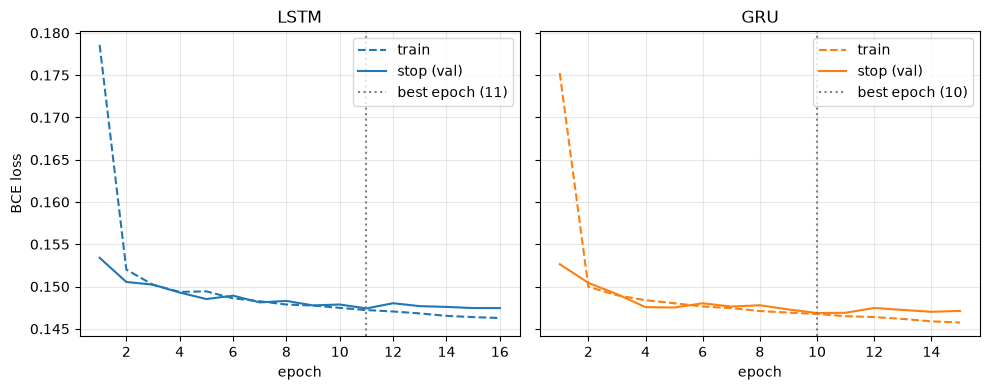

In [7]:
from src.models.evaluation.optuna_history import plot_training_history

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
history_fig = plot_training_history(
    tuple(MODELS), save_path=COMPARISON_DIR / "training_history.png"
)
plt.show()

## 4. Test

For each model, the threshold was already selected on `tune` and is now frozen. The final refit uses all of February (`development`) for the `best_epoch` found during tuning. March is then predicted once.

A checkpoint with the architecture, parameters, threshold and epoch count is saved to `artifacts/sherlock_w2/<model>/checkpoints/<model>.pt`. The refit time is also recorded, so the comparison can report time per epoch.

In [8]:
from src.models.recurrent_models.test import test_model


def make_builder(model_cls):
    """Build ``model_cls`` from the tuned hyper-parameters."""
    def build(best_params, input_dim):
        return model_cls(
            input_dim=input_dim,
            hidden_dim=int(best_params["hidden_dim"]),
            layer_dim=int(best_params["layer_dim"]),
            output_dim=OUTPUT_DIM,
        )
    return build


results = {}
for name, model_cls in MODELS.items():
    print(f"\n===== {name.upper()} =====")
    results[name] = test_model(
        best[name]["best_params"],
        data,
        threshold=best[name]["threshold"],
        best_epoch=best[name]["best_epoch"],
        device=DEVICE,
        seed=SEED,
        verbose=True,
        build_model=make_builder(model_cls),
        model_name=name,
    )

pd.DataFrame(
    {
        name.upper(): {
            "test users": len(result["proba_test"]),
            "predicted churn rate": result["pred_test"].mean(),
            "threshold": result["threshold"],
            "epochs": result["epochs"],
            "seconds / epoch": result["seconds_per_epoch"],
            "checkpoint": str(result["checkpoint"]),
        }
        for name, result in results.items()
    }
)


===== LSTM =====
final | epoch 01 | train=0.17174
final | epoch 02 | train=0.15138
final | epoch 03 | train=0.15051
final | epoch 04 | train=0.14984
final | epoch 05 | train=0.14929
final | epoch 06 | train=0.14898
final | epoch 07 | train=0.14838
final | epoch 08 | train=0.14802
final | epoch 09 | train=0.14799
final | epoch 10 | train=0.14754
final | epoch 11 | train=0.14712

===== GRU =====
final | epoch 01 | train=0.16913
final | epoch 02 | train=0.14970
final | epoch 03 | train=0.14869
final | epoch 04 | train=0.14808
final | epoch 05 | train=0.14760
final | epoch 06 | train=0.14735
final | epoch 07 | train=0.14698
final | epoch 08 | train=0.14670
final | epoch 09 | train=0.14651
final | epoch 10 | train=0.14638


,LSTM,GRU
test users,970960,970960
predicted churn rate,0.084043,0.077326
threshold,0.27,0.24
epochs,11,10
seconds / epoch,18.112008,16.621176
checkpoint,artifacts/sherlock_w2/lstm/checkpoints/lstm.pt,artifacts/sherlock_w2/gru/checkpoints/gru.pt


## 5. Per-model diagnostics

`evaluate_model` writes the complete evaluation of each model to `artifacts/sherlock_w2/<model>/evaluation/`:

- `test` metrics at the `tune` threshold,
- complementary metrics at `0.5`,
- classification report,
- confusion matrix,
- reliability/histogram,
- threshold manifest,
- training history of the best trial.

These are internal diagnostics, so they are shown **one model at a time**. The direct comparison (ROC/PR, gain/lift, tables) is in section 6.

`log_loss` measures probability quality. `ROC-AUC` and `average_precision` measure ranking. `F1`, `precision` and `recall` measure decisions at the chosen threshold.

In the confusion matrix:

- **FN**: churners the model missed.
- **FP**: loyal customers flagged as at risk.

Each threshold was selected in February and is not optimised again in March.

In [9]:
from src.models.evaluation import evaluate_model

reports = {
    name: evaluate_model(
        results[name],
        best[name],
        data,
        model_name=name,
        show_plots=False,
    )
    for name in MODELS
}
pd.concat([report["display"] for report in reports.values()], ignore_index=True)

,model_id,family,input,n_channels,n_parameters,best_epoch,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,LSTM,lstm,sequence,20,15457,11,0.14674,0.20384,0.85030,0.58075,0.05412,0.92714,0.76268,0.60162,0.56216,0.96321,0.58122,0.77066,0.54174,0.27
1,GRU,gru,sequence,20,11617,10,0.14653,0.20707,0.84955,0.58081,0.05501,0.92991,0.75433,0.62837,0.54023,0.96842,0.58097,0.77137,0.54482,0.24



===== LSTM =====
confusion_png -> artifacts/sherlock_w2/lstm/evaluation/figures/confusion/confusion_LSTM_test.png


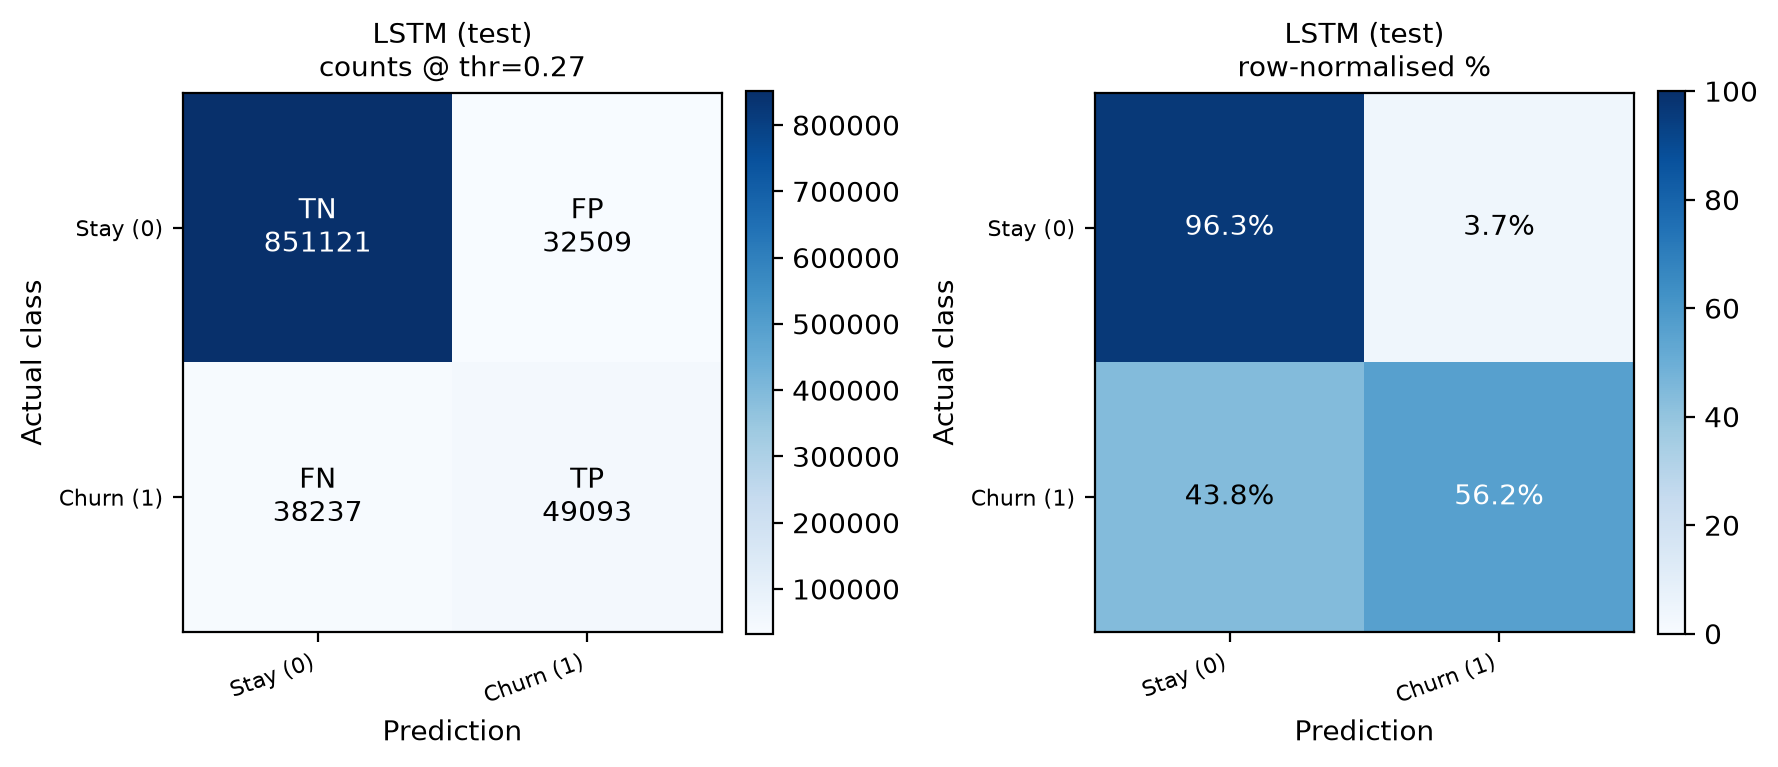

calibration -> artifacts/sherlock_w2/lstm/evaluation/figures/curves/calibration_hist.png


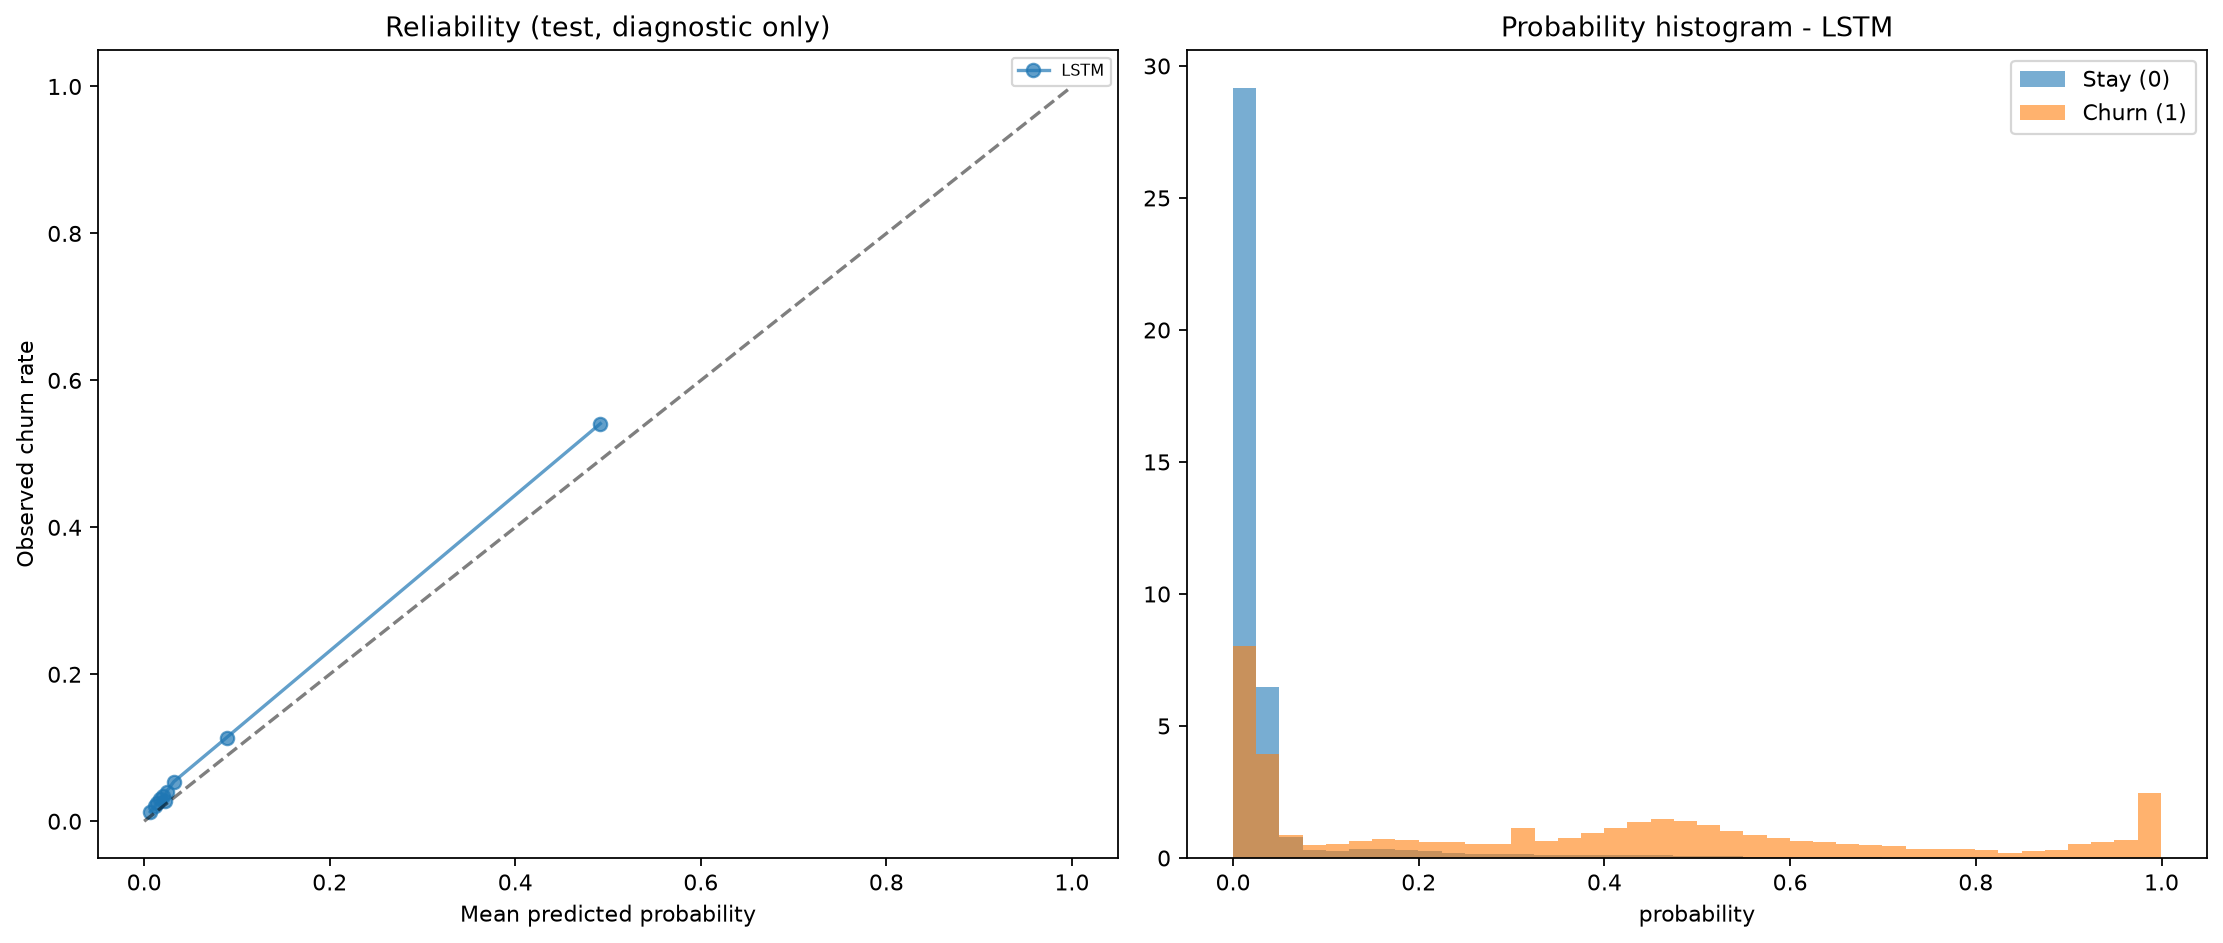

optuna_history -> artifacts/sherlock_w2/lstm/evaluation/figures/lstm_training_history.png


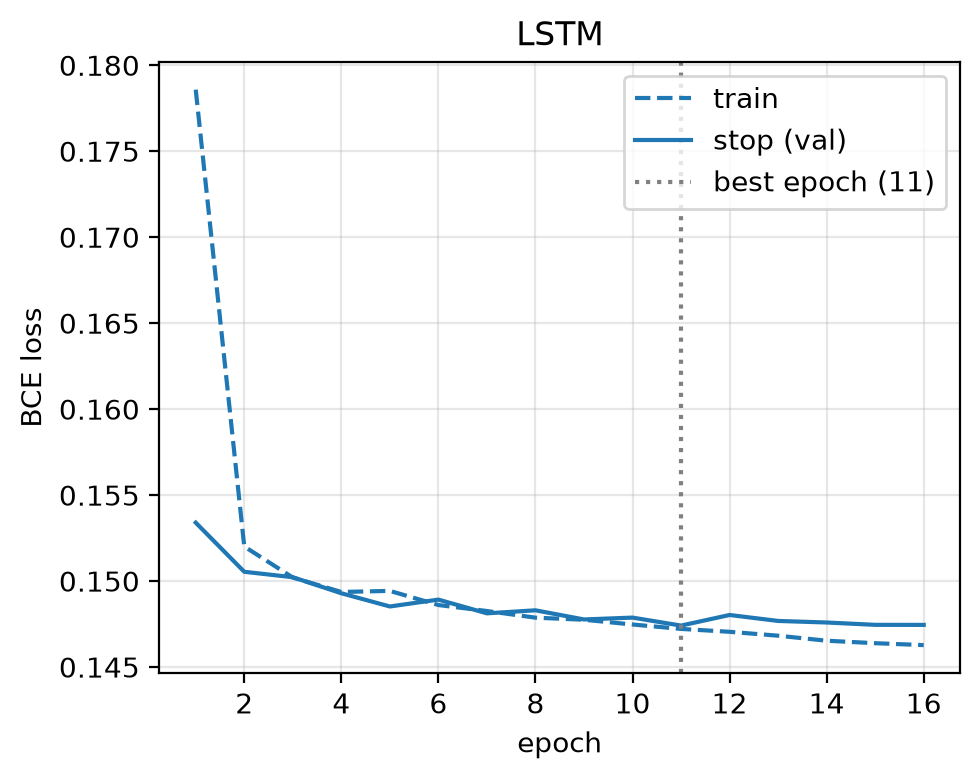


===== GRU =====
confusion_png -> artifacts/sherlock_w2/gru/evaluation/figures/confusion/confusion_GRU_test.png


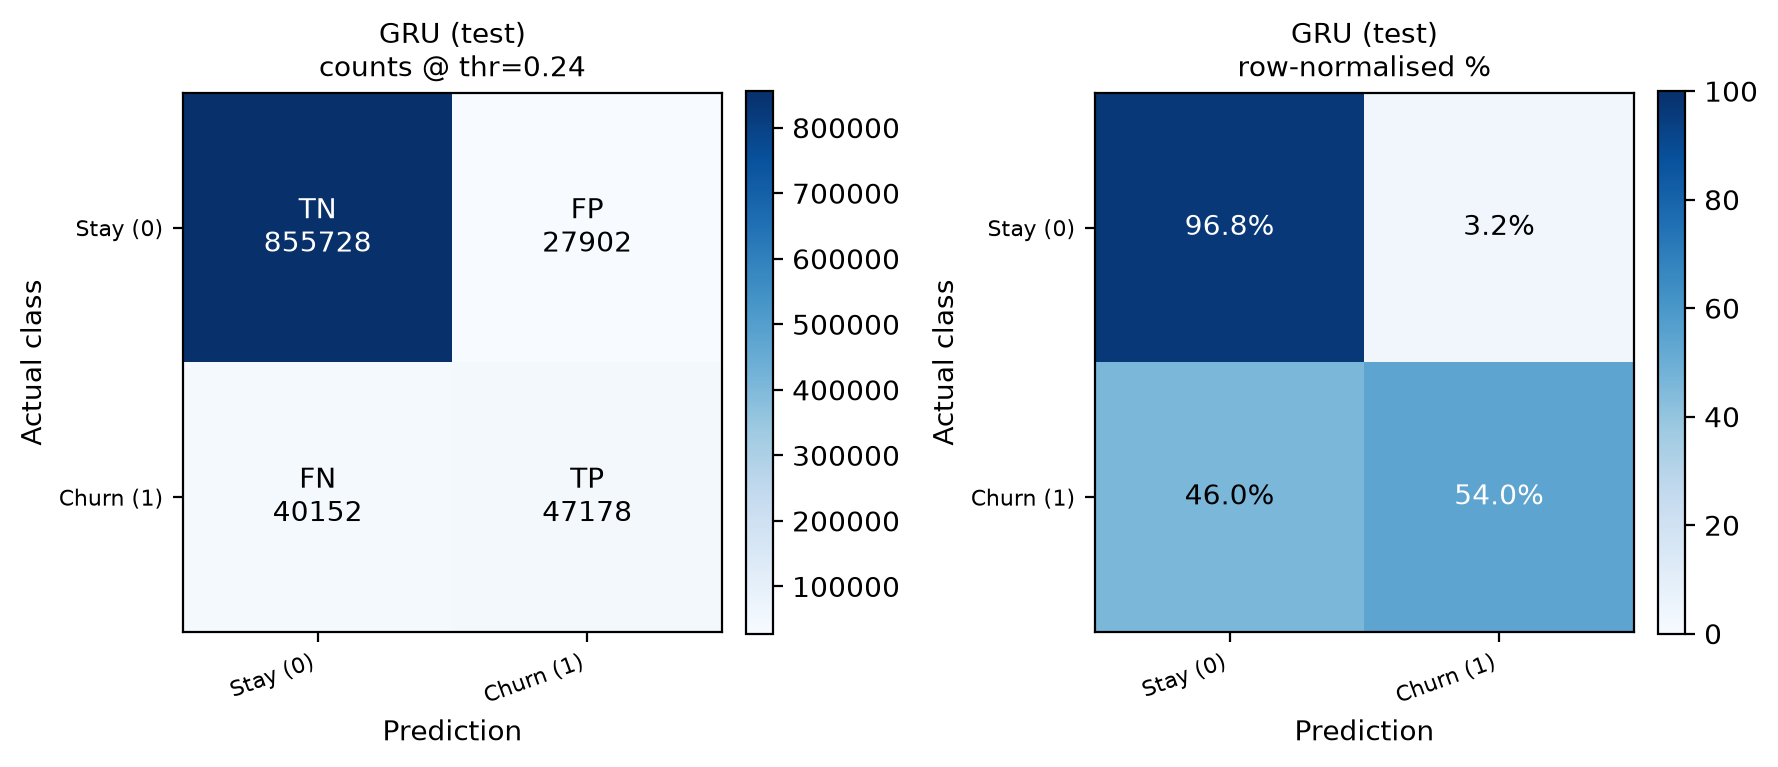

calibration -> artifacts/sherlock_w2/gru/evaluation/figures/curves/calibration_hist.png


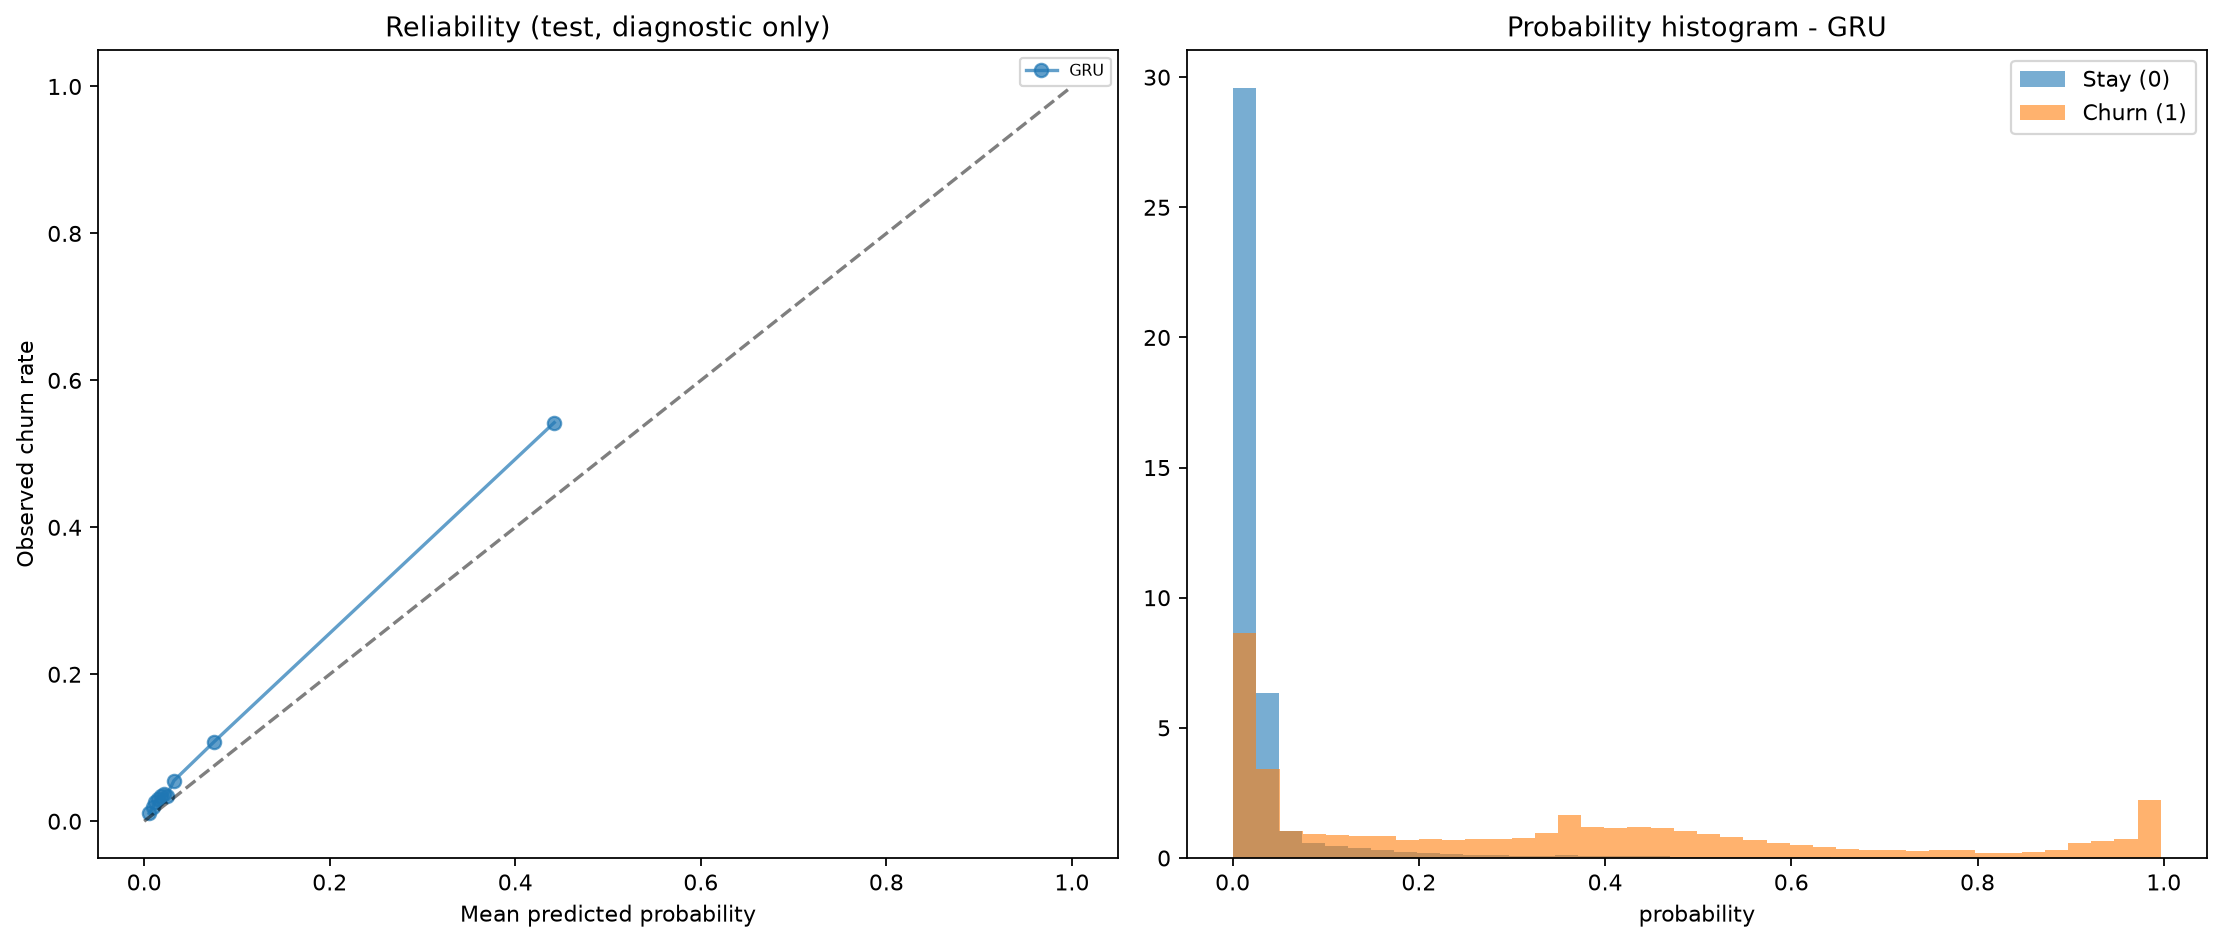

optuna_history -> artifacts/sherlock_w2/gru/evaluation/figures/gru_training_history.png


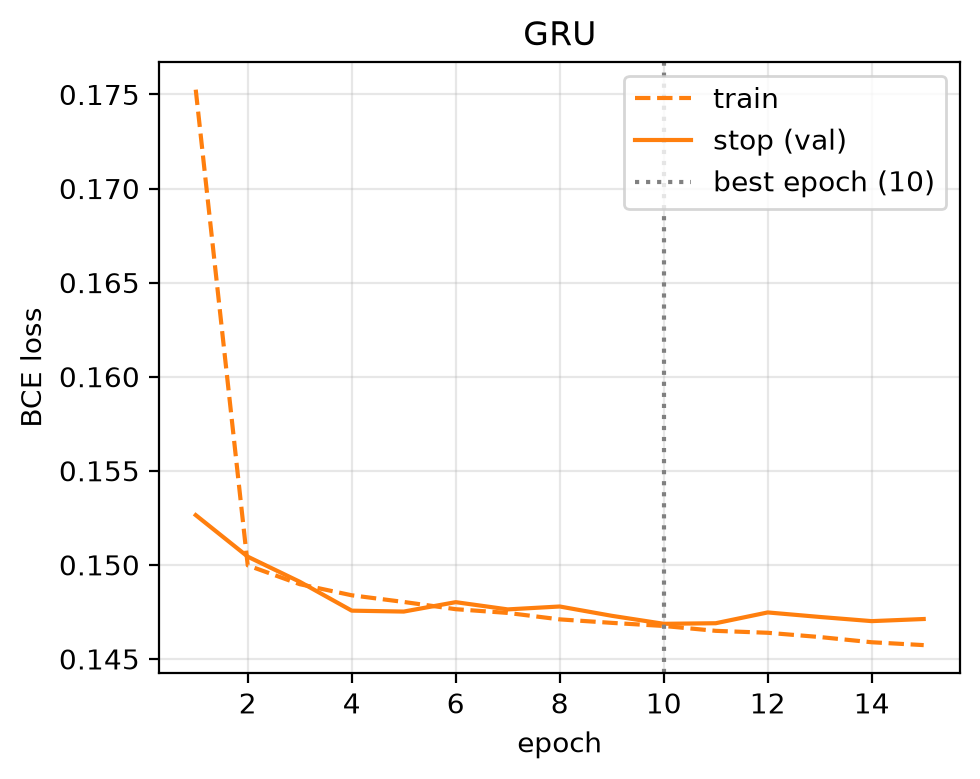

In [10]:
for name, report in reports.items():
    print(f"\n===== {name.upper()} =====")
    for key in ("confusion_png", "calibration", "optuna_history"):
        path = report["paths"].get(key)
        if path is not None and Path(path).is_file():
            print(key, "->", path)
            display(Image(filename=str(path)))

## 6. LSTM vs GRU comparison

`compare_models` puts both models on the same axes and in the same tables, with LSTM always in blue and GRU always in orange:

- **ROC and Precision-Recall**, one line per model. PR is the more informative one because churn is the minority class.
- **Cumulative gain and lift**: share of churners captured when contacting the top-risk users first, for retention campaigns.
- **Metrics table**: AUC-ROC, AUC-PR, F1, log-loss, parameters and time per epoch, with the best value of each column in bold.
- **Paired bootstrap** (1000 resamples of the test users): 95% intervals per model and for the difference LSTM − GRU. Both models are scored on the same resampled users, so the interval of the difference accounts for their correlation. A difference is significant when its interval excludes 0.
- **DeLong test** for the difference in AUC-ROC.
- **Best hyper-parameters** of each model (annex table).

Every metric uses each model's own `tune` threshold; nothing is tuned on `test`.

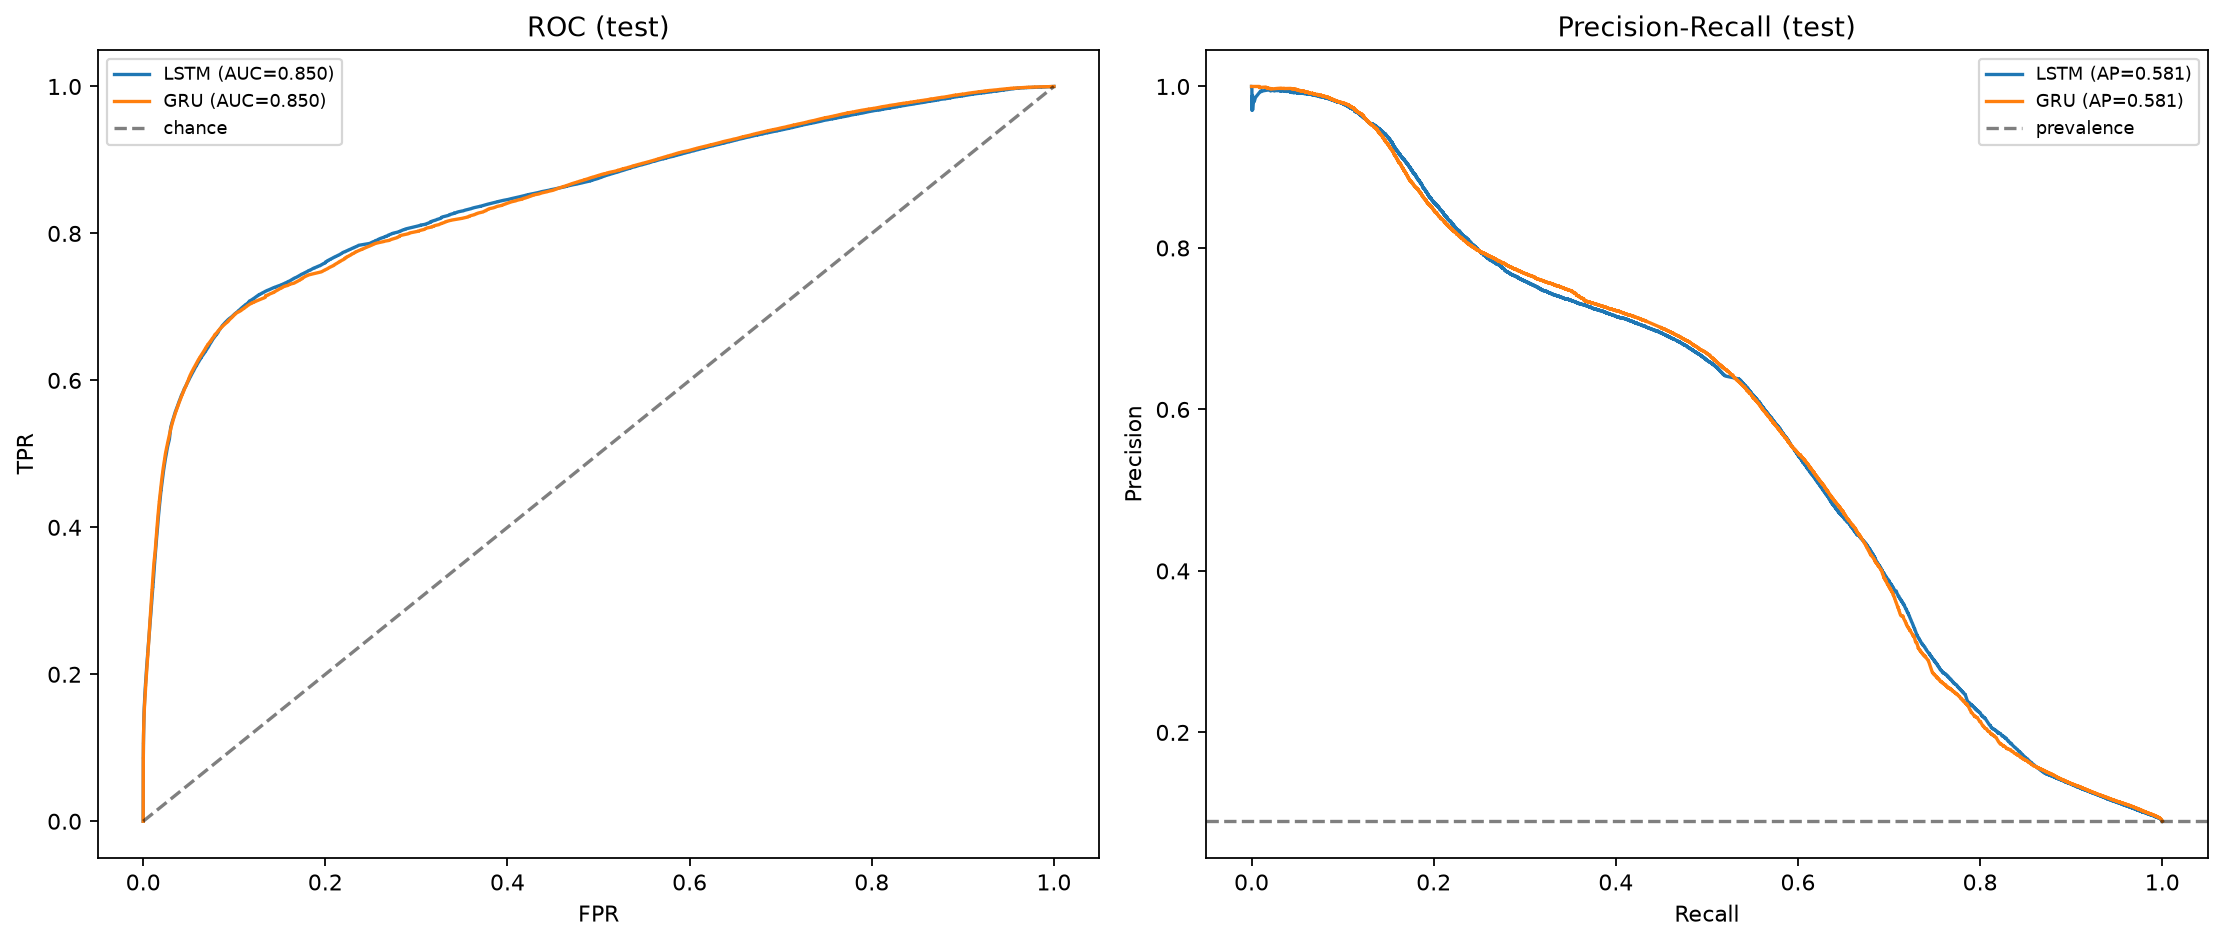

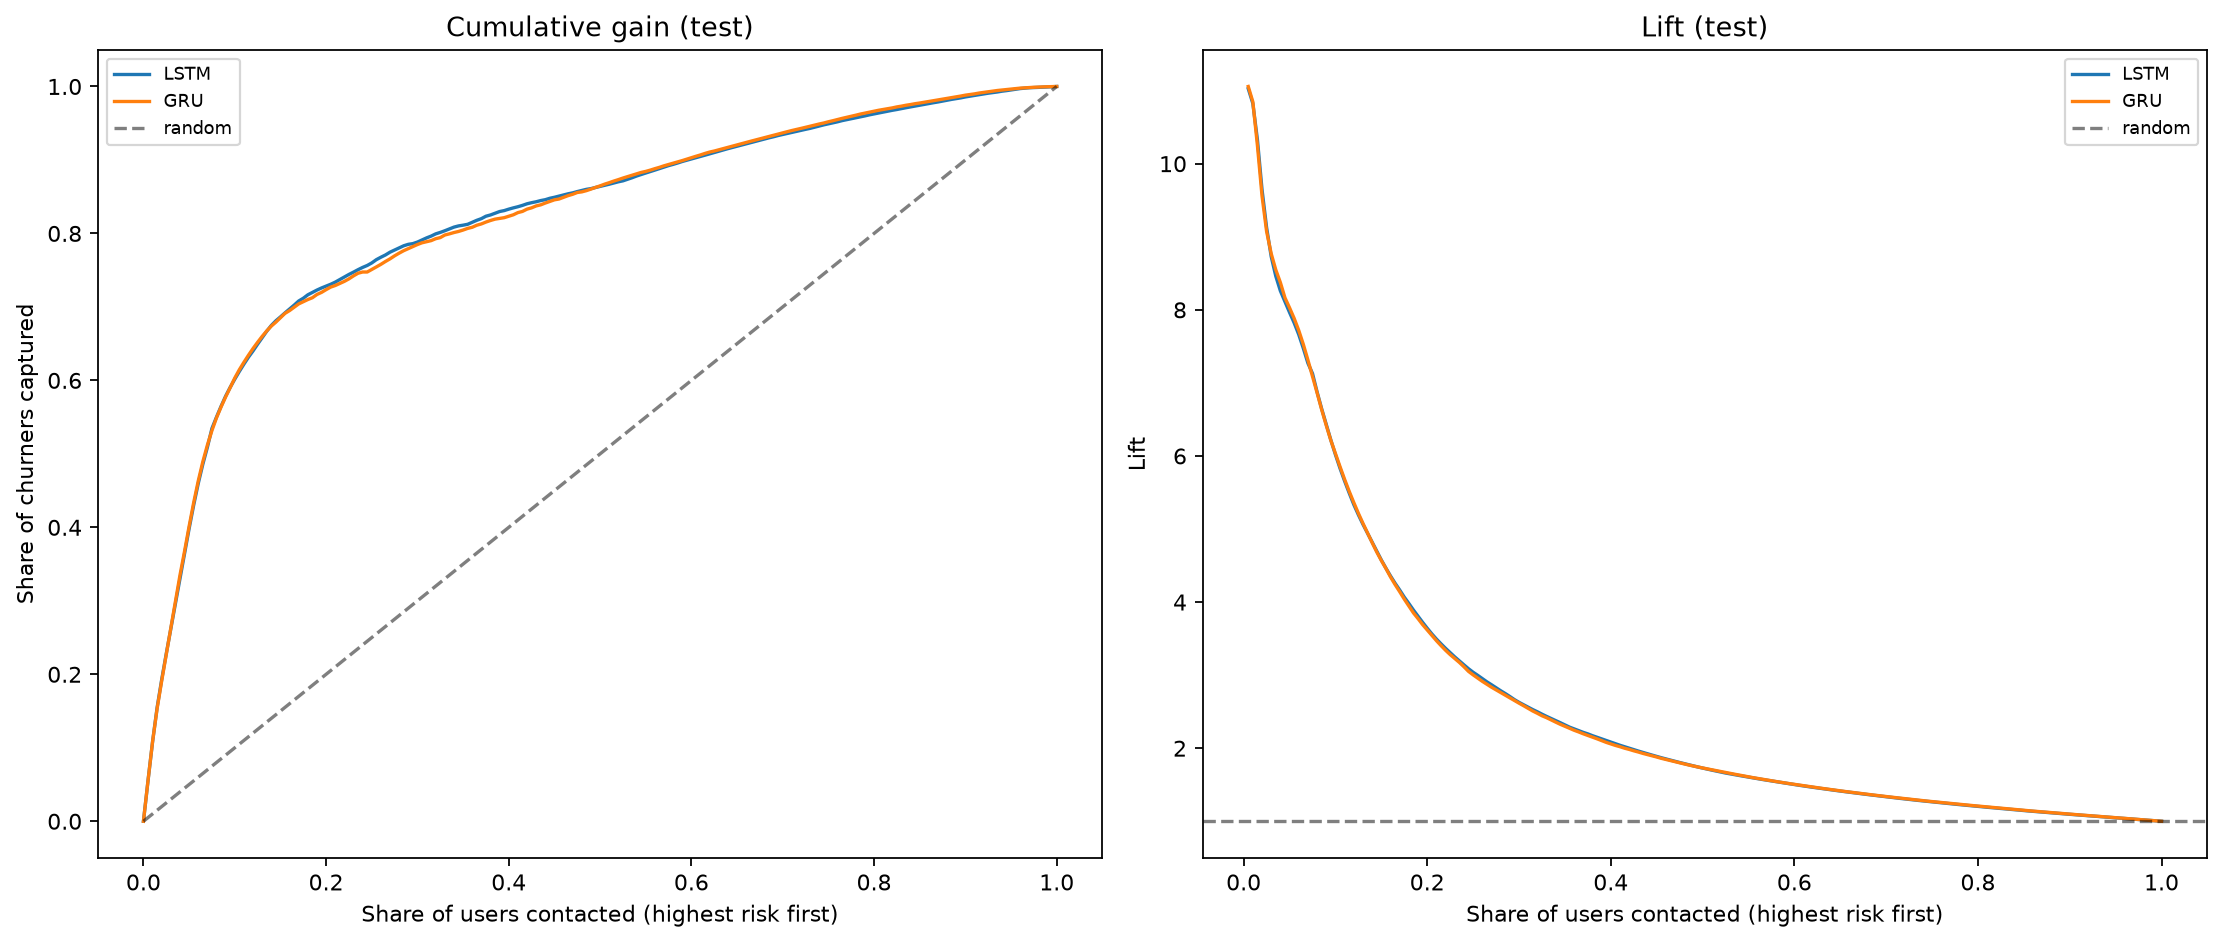

,AUC-ROC,AUC-PR,F1,Log-loss,Parámetros,Tiempo/época (s),Umbral
Modelo,,,,,,,
LSTM,0.8503,0.5808,0.5812,0.2038,"15,457",18.11,0.27
GRU,0.8495,0.5808,0.5810,0.2071,"11,617",16.62,0.24


In [11]:
from src.models.evaluation import compare_models

comparison = compare_models(runs=results, tunes=best, show_plots=False)

for key in ("roc_pr", "gain_lift"):
    display(Image(filename=str(comparison["paths"][key])))

comparison["display"]

In [12]:
print("Paired bootstrap, 95% CI (difference = LSTM - GRU)")
display(comparison["bootstrap"])

delong = comparison["delong"]
print(
    f"DeLong AUC-ROC: {delong['model_a']}={delong['auc_a']:.4f}"
    f" | {delong['model_b']}={delong['auc_b']:.4f}"
    f" | diff={delong['diff']:+.4f} | z={delong['z']:.2f} | p={delong['p_value']:.3g}"
)

print("\nGain and lift at fixed contact rates")
display(comparison["lift"].round(3))

print("Best hyper-parameters (annex)")
display(comparison["hyperparams"])

Paired bootstrap, 95% CI (difference = LSTM - GRU)


,LSTM,LSTM IC95,GRU,GRU IC95,Δ LSTM-GRU,Δ IC95,Significativo
Métrica,,,,,,,
AUC-ROC,0.850302,"[0.8487, 0.8519]",0.849549,"[0.8480, 0.8511]",0.000752,"[0.0001, 0.0014]",True
AUC-PR,0.580755,"[0.5774, 0.5840]",0.580812,"[0.5774, 0.5842]",-0.000057,"[-0.0009, 0.0006]",False
F1,0.581216,"[0.5783, 0.5839]",0.580974,"[0.5780, 0.5837]",0.000242,"[-0.0009, 0.0014]",False
Log-loss,0.203844,"[0.2026, 0.2051]",0.207070,"[0.2058, 0.2084]",-0.003227,"[-0.0034, -0.0030]",True


DeLong AUC-ROC: LSTM=0.8503 | GRU=0.8495 | diff=+0.0008 | z=2.47 | p=0.0134

Gain and lift at fixed contact rates


Churners capturados          Lift       
Modelo                        LSTM    GRU   LSTM    GRU
Top contactado                                         
5%                           0.398  0.401  7.964  8.028
10%                          0.602  0.603  6.017  6.032
20%                          0.728  0.723  3.642  3.617
30%                          0.788  0.785  2.628  2.616

Best hyper-parameters (annex)


,layer_dim,hidden_dim,lr,weight_decay,batch_size,best_epoch,trial,tune log-loss
Modelo,,,,,,,,
LSTM,2,32,0.002285,0.000537,512,11,0,0.146742
GRU,2,32,0.002285,0.000537,512,10,0,0.146528


## 7. Artifacts and limitations

Generated artifacts:

```text
artifacts/sherlock_w2/
├── feature_preparation/          # split, labels and scalers (shared)
├── lstm/
│   ├── optuna/                   # study, trials, best params, best-trial history
│   ├── checkpoints/lstm.pt       # final model
│   └── evaluation/
│       ├── metrics/
│       ├── figures/
│       └── selection_manifest.json
├── gru/                          # same layout as lstm/
│   ├── optuna/
│   ├── checkpoints/gru.pt
│   └── evaluation/
└── comparison/
    ├── roc_pr_comparison.png
    ├── gain_lift_comparison.png
    ├── training_history.png
    ├── comparison_metrics.csv
    ├── bootstrap_ci.csv
    ├── delong_auc.json
    ├── gain_lift_cutoffs.csv
    └── best_hyperparams.csv
```

Limitations:

- There is only one test month: March.
- Validation is used for early stopping, tuning and the threshold, so validation metrics are optimistic.
- No probability calibration was applied.
- Each final model is trained with a single seed. The bootstrap intervals cover sampling noise in the test set, not the variation from weight initialisation; a small gap between LSTM and GRU could change with another seed.
- Time per epoch is measured on the final refit and is only comparable when both models run on the same device.
- Churn prevalence changes between February and March; that shift is part of the honest evaluation.